# Analyse G-ring Event Data

## Notebook Overview
This notebook runs event-wise processing for G-ring data with focus on Love-wave backazimuth and dispersion diagnostics.

**Main workflow**
- Load G-ring event configuration and data.
- Apply core preprocessing and filtering.
- Compute backazimuth estimates/maps.
- Derive Love-wave velocity/dispersion products.
- Export event-level plots for review.

The data of the vertical component for the G-ring is used for Love wave analysis

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from sixdegrees.sixdegrees import sixdegrees

from sixdegrees.plots.plot_waveform_cc import plot_waveform_cc
from sixdegrees.plots.plot_cwt_all import plot_cwt_all
from sixdegrees.plots.plot_velocities import plot_velocities
from sixdegrees.plots.plot_backazimuth_results import plot_backazimuth_results
from sixdegrees.plots.plot_spectra_comparison_fill import plot_spectra_comparison_fill
from sixdegrees.plots.plot_backazimuth_map import plot_backazimuth_map
from sixdegrees.plots.plot_dispersion_curves import plot_dispersion_curves
from sixdegrees.plots.plot_dispersion_traces import plot_dispersion_traces

## Configurations

In [3]:
# set date
date = '20230908'
# date = '20230912'
# date = '20231202' # no data
# date = '20231203' # no data

# date = '20240314'
# date = '20240322'
# date = '20240323'
# date = '20240414'
# date = '20240422'
# date = '20240815'
# date = '20241023'
# date = '20240915'

# date = '20250602'
# date = '20250513'
# date = '20251206' # no data
# date = '20251212' # no data
# date = '20251227' # no data

# date = '20260107' # no data

# set if figures are saved
save_figures = True


Load the configuration for the event

In [4]:
config = sixdegrees.load_from_yaml(f"./events/event_{date}/config_gring_{date}.yml")

In [5]:
# check if path to figures exists
if save_figures and not os.path.exists(config['path_to_figures']):
    os.makedirs(config['path_to_figures'])


Setup a sixdegrees object

In [6]:
sd = sixdegrees(conf=config)

Get key information about the event

In [7]:
ev = sd.get_event_info(
    origin_time=config['origin_time'],
    base_catalog="USGS",
    magnitude=config['magnitude']
)

Found event:
Origin time: 2023-09-08T22:11:01.405000Z
Magnitude: 6.8 mww
Location: 31.058°N, -8.385°E
Depth: 19.0 km
Epicentral Distance: 2686.73 km
Epicentral Distance: 24.2°
Backazimuth: 229.50°


Let's load the data based on the configuration file. We also apply a resampling.

In [8]:
sd.load_data(config['tbeg'], config['tend'], resample_rate=5)

-> fetching XX.RLAS..BHZ data from mseed file
-> fetching XX.RLAS..BHN data from mseed file
-> fetching XX.RLAS..BHE data from mseed file
3 Trace(s) in Stream:
XX.RLAS..BHZ | 2023-09-08T22:14:29.024999Z - 2023-09-08T22:43:01.024999Z | 20.0 Hz, 34241 samples
XX.RLAS..BHN | 2023-09-08T22:14:29.024999Z - 2023-09-08T22:43:01.024999Z | 20.0 Hz, 34241 samples
XX.RLAS..BHE | 2023-09-08T22:14:29.024999Z - 2023-09-08T22:43:01.024999Z | 20.0 Hz, 34241 samples
-> fetching XX.RLAS..BJZ data from mseed file
1 Trace(s) in Stream:
XX.RLAS..BJZ | 2023-09-08T22:14:28.977249Z - 2023-09-08T22:43:00.977249Z | 20.0 Hz, 34241 samples
-> resampling stream to 5 Hz
4 Trace(s) in Stream:
XX.RLAS..LHZ | 2023-09-08T22:14:29.024999Z - 2023-09-08T22:43:00.824999Z | 5.0 Hz, 8560 samples
XX.RLAS..LHN | 2023-09-08T22:14:29.024999Z - 2023-09-08T22:43:00.824999Z | 5.0 Hz, 8560 samples
XX.RLAS..LHE | 2023-09-08T22:14:29.024999Z - 2023-09-08T22:43:00.824999Z | 5.0 Hz, 8560 samples
XX.RLAS..LJZ | 2023-09-08T22:14:28.977249

Ensure that all traces of stream have the same sample size

In [9]:
sd.trim_stream(set_common=True, set_interpolate=True)

 -> trim_stream: window 2023-09-08T22:14:29.024999Z -> 2023-09-08T22:43:00.777249Z
    initial npts=[8560, 8560, 8560, 8560], rates=[5.0]
    linear interpolation -> 5.0 Hz, anchored at 2023-09-08T22:14:29.024999Z
    final: starttimes={'2023-09-08T22:14:29.024999Z'}, npts={8559}, rates={5.0}


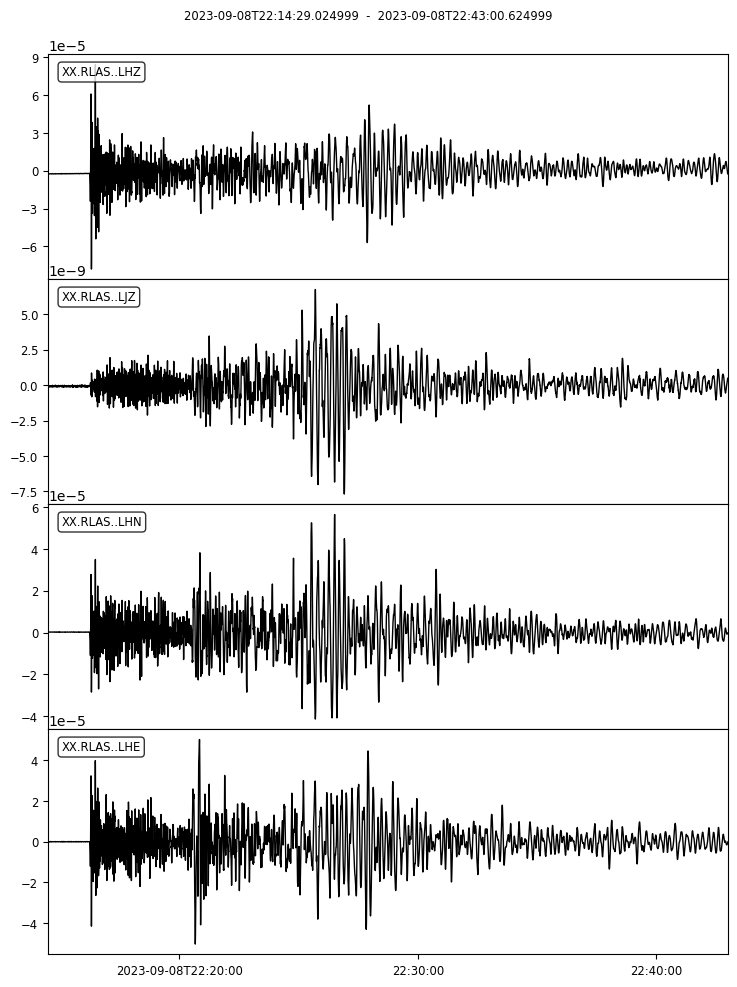

In [10]:
sd.st.plot(equal_scale=False);

## Analysis

Frequency band to filter (this is applied to the stream object after being reset to raw stream)

In [11]:
sd.filter_data(fmin=config['fmin'], fmax=config['fmax'], output=False)

Apply polarity correction if needed. This is applied to the stream object that is processed. If raw is True, the polarity correction is applied to the raw stream too.

In [12]:
sd.polarity_stream(pol_dict={"HZ": -1, "JZ": 1}, raw=True)

-> polarity for channel HZ changed from 1 to -1


Cut bad data if specified in config file

In [13]:
if 'time_cuts' in config:
    for key, values in config['time_cuts'].items():
        for value in values:
            sd.replace_values_in_window(tbeg=value[0], tend=value[1], value=0, channel_list=[key])

Now, let's compare the waveforms of the rotation (red) and translational (black) components 

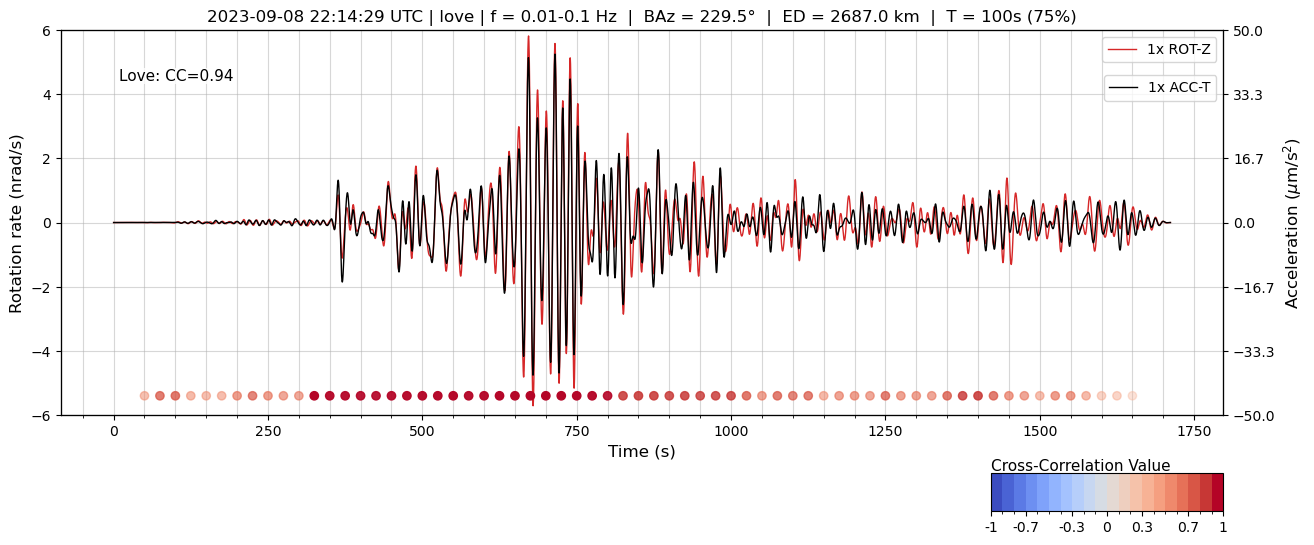

In [14]:
fig = plot_waveform_cc(
    sd_object=sd,
    twin_sec=config['twin_sec'],
    twin_overlap=config['twin_overlap'],
    wave_type="love"
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_gring_waveform_cc.png", dpi=150, bbox_inches='tight')

Add time cuts with bad data to config file

In [35]:
# from obspy import UTCDateTime

# time_cuts = {
#     "JN": [(str(UTCDateTime(config['tbeg'])+4000), str(UTCDateTime(config['tbeg'])+4200)),
#           (str(UTCDateTime(config['tbeg'])+1000), str(UTCDateTime(config['tbeg'])+1300))],
#     "JE": [(str(UTCDateTime(config['tbeg'])+4000), str(UTCDateTime(config['tbeg'])+4200)),
#           (str(UTCDateTime(config['tbeg'])+1000), str(UTCDateTime(config['tbeg'])+1300))],
#     "JZ": [(str(UTCDateTime(config['tbeg'])+1000), str(UTCDateTime(config['tbeg'])+1300))],
#     }
# if 'time_cuts' not in config:
#     config['time_cuts'] = time_cuts
# else:
#     config['time_cuts'] = {**config['time_cuts'], **time_cuts}

# # get date
# date = config['origin_time'][:10].replace('-', '')

# # define filename
# filename = f"./events/event_{date}/config_{date}.yml"

# os.remove(filename)

# # store the configuration as a yaml file
# sd.store_as_yaml(config, filename)

Make spectra for the raw data

In [36]:
# # Plot the spectra comparison
# fig = plot_spectra_comparison_fill(
#     sd_object=sd,
#     fmin=0.01,
#     fmax=1.0,
#     ylog=False,
#     xlog=True,
#     fill=True # fill spectra
# )

# if save_figures:
#     fig.savefig(f"{config['path_to_figures']}{date}_spectra_comparison.png")

### Backazimuth Estimate

Computation of backazimuth results for Love waves using the midpoint CC-method

baz_max = 237, baz_std = 13


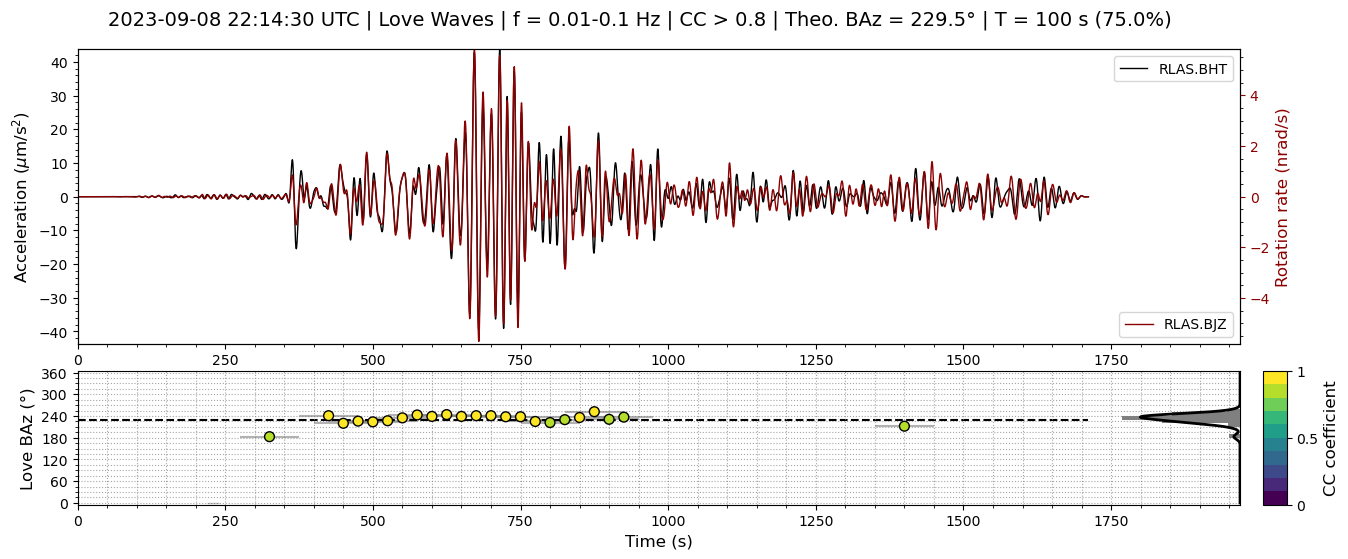

In [37]:
# First compute backazimuth
baz_results_love = sd.compute_backazimuth(
    wave_type='love',
    baz_step=config['baz_step'],
    baz_win_sec=config['twin_sec'],
    baz_win_overlap=config['twin_overlap'],
    out=True
)

# Then plot results
fig = plot_backazimuth_results(
    sd,
    baz_results_love,
    wave_type='love',
    cc_method='mid',
    baz_theo=ev['backazimuth'],
    cc_threshold=config['cc_threshold'],
)
if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_gring_backazimuth_love_mid.png")

Show backazimuth estimates for the event on a map

In [38]:
results_map = sd.compute_backazimuth_map(
    wave_types=['love'],
    baz_win_sec=config['twin_sec'],
    baz_win_overlap=config['twin_overlap'],
    cc_threshold=config['cc_threshold'],
)

Using precomputed love backazimuth results


ERROR plotting theoretical great circle: Format specifier missing precision


/home/andbro/Downloads/SixDegreesOfFreedom/sixdegrees/plots/plot_backazimuth_map.py:616: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


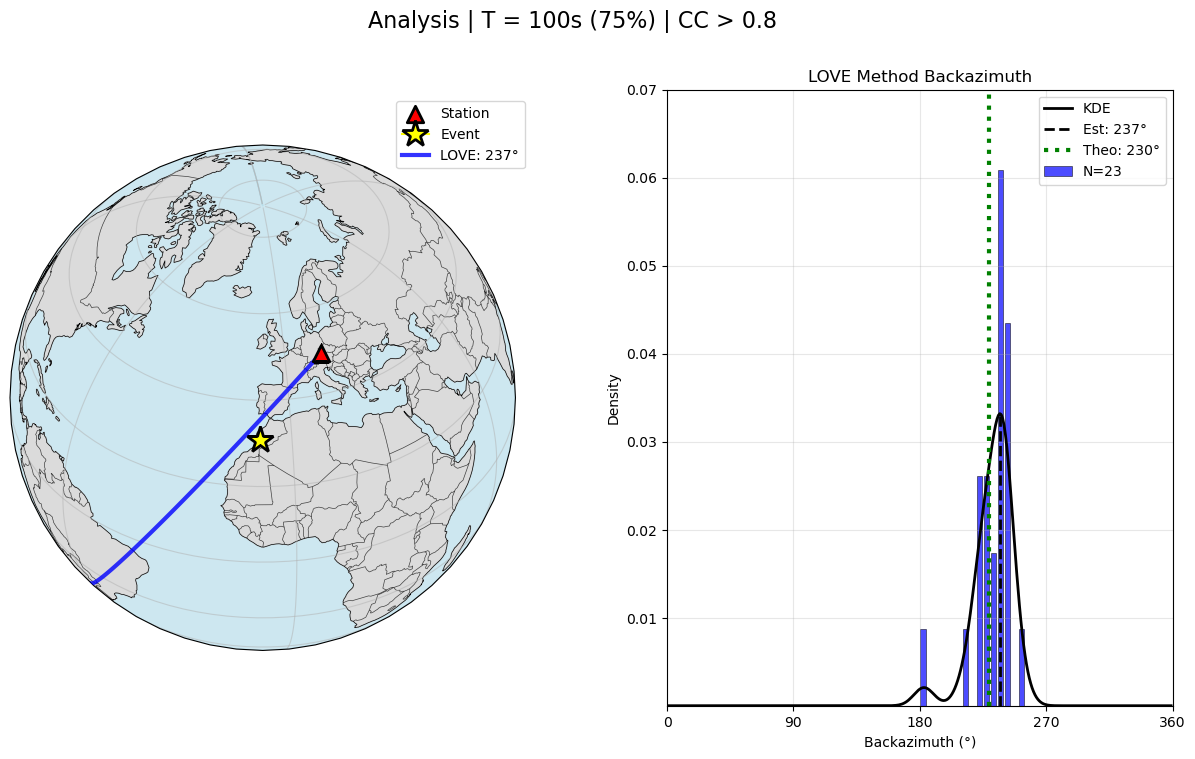

In [39]:
fig = plot_backazimuth_map(
    results_map,
    event_info=ev,
    map_projection='orthographic',  # 'orthographic' or 'platecarree'
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_gring_backazimuth_map.png")

### Analyse phase velocities

In [40]:
# Compute Love wave velocities
love_velocities = sd.compute_velocities(
    wave_type='love',
    win_time_s=config['twin_sec'],
    overlap=config['twin_overlap'],
    cc_threshold=config['cc_threshold'],
    method='odr',  # 'odr' | 'ransac'
    # baz=ev['backazimuth']  # theoretical backazimuth (optional)
)

Using event BAZ 229.5


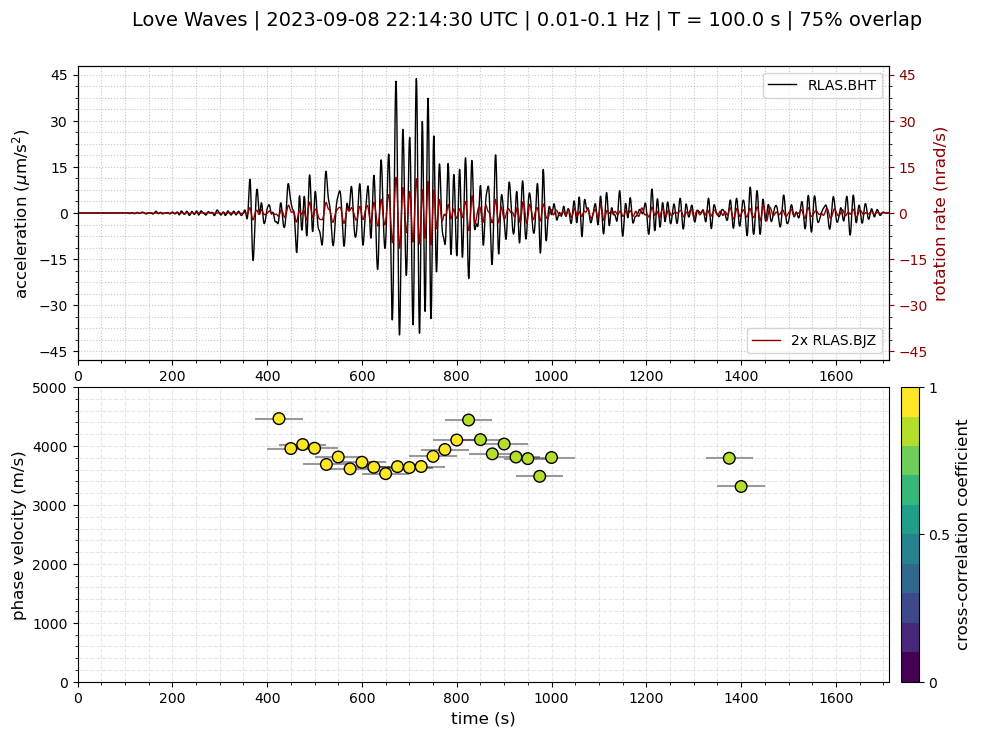

In [41]:
# Plot results
fig = plot_velocities(sd,
    velocity_results=love_velocities,
    vmax=5000,  # optional
    minors=True # optional
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_gring_velocities_love.png")


### Get Dispersion Plots

In [42]:
params = {
    'fmin': 0.01,
    'fmax': 0.5,
    'octave_fraction': 3,
    'window_factor': 6.0,
    'cc_threshold': 0.7,
    'cc_method': 'mid',
    'baz_step': 1,
    'time_window_overlap': 0.25,
}

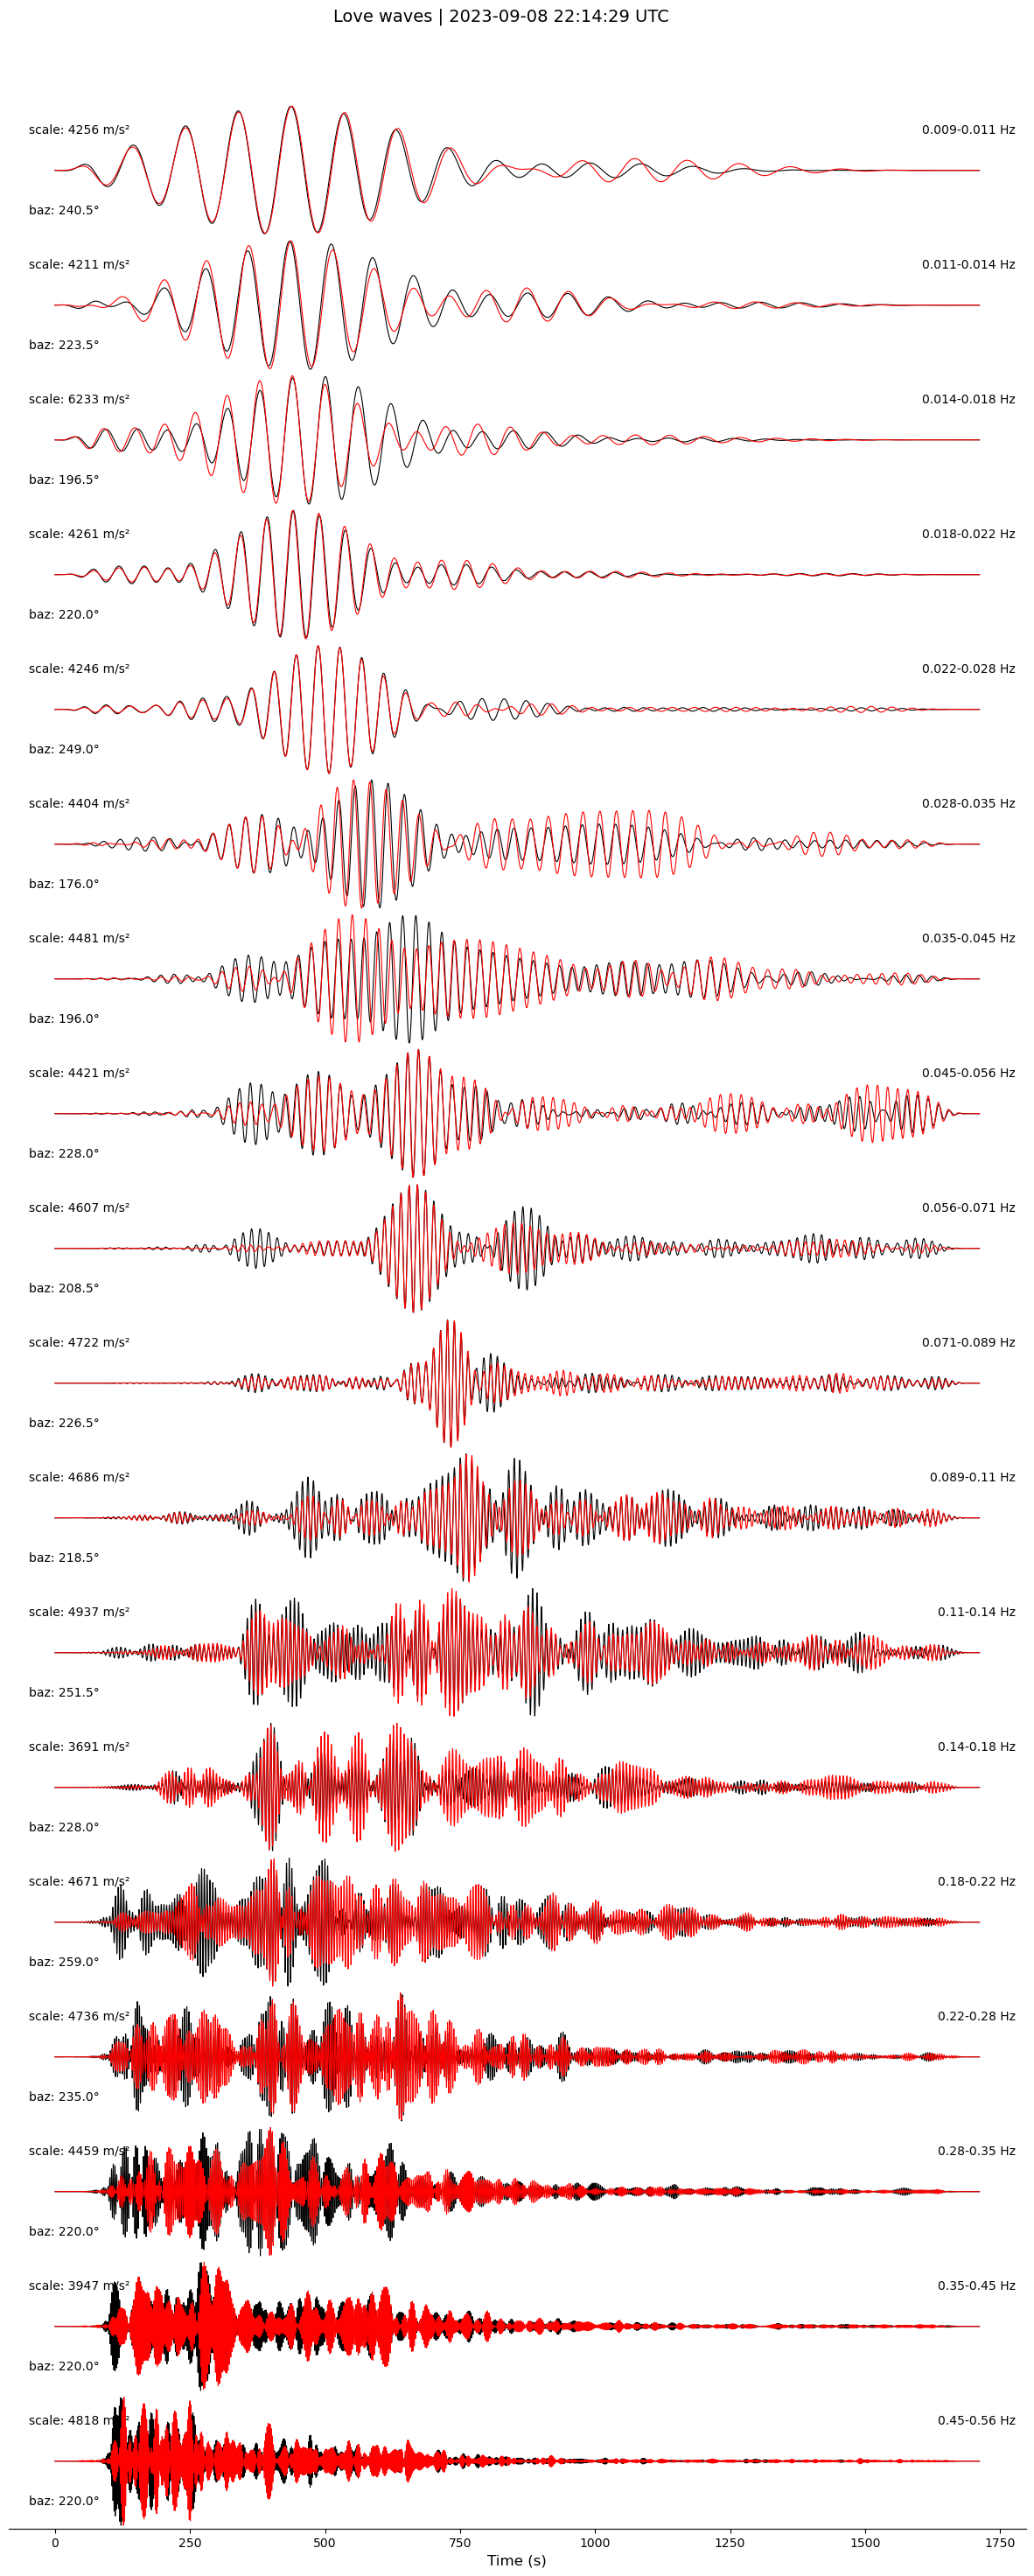

In [43]:
# Compute dispersion curve for Love waves
love_results_odr = sd.compute_dispersion_curve(
    wave_type="love",
    fmin=params['fmin'],              # Minimum frequency in Hz
    fmax=params['fmax'],               # Maximum frequency in Hz
    octave_fraction=params['octave_fraction'],      # 1/3 octave bands
    window_factor=params['window_factor'],      # Time window = window_factor / fc
    cc_threshold=params['cc_threshold'],       # Cross-correlation threshold
    cc_method=params['cc_method'],           # Cross-correlation method: 'mid' or 'max'
    time_window_overlap=0.5,    # Backazimuth window overlap
    velocity_method='odr',  # Regression method: 'odr', 'ransac', etc.
    zero_intercept=True,    # Force zero intercept
    verbose=False,            # Print progress
    n_jobs=3            # Number of parallel jobs
)


fig_traces_love = plot_dispersion_traces(
    dispersion_results=love_results_odr,
    unitscale="nano",
    data_type="acceleration"
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_gring_dispersion_love_{params['cc_method']}.png")
    


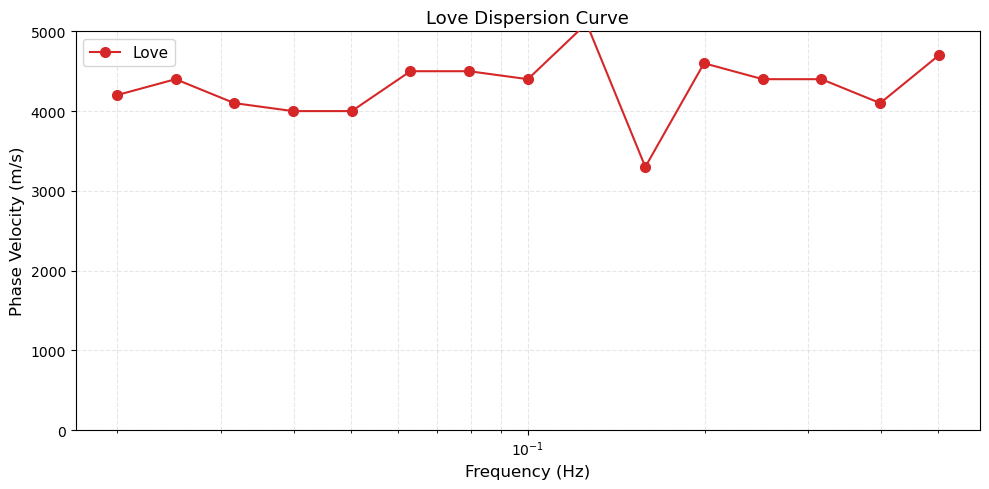

In [47]:
fig_curves = plot_dispersion_curves(
    love_results=love_results_odr,
    figsize=(10, 5),
    xlog=True,                 # Logarithmic x-axis
    ylog=False,                 # Logarithmic y-axis
    markersize=7,
    linewidth=1.5,
    title="Love Dispersion Curve",  # Optional
    show_errors=False            # Show error bars from KDE deviations
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_gring_dispersion_curves.png")


## Get Full Event Analysism

In [45]:
from sixdegrees.plots.plot_event_overview import plot_event_overview

Theoretical P-arrival: 2023-09-08T22:16:16.309218Z
Theoretical S-arrival: 2023-09-08T22:20:34.498083Z


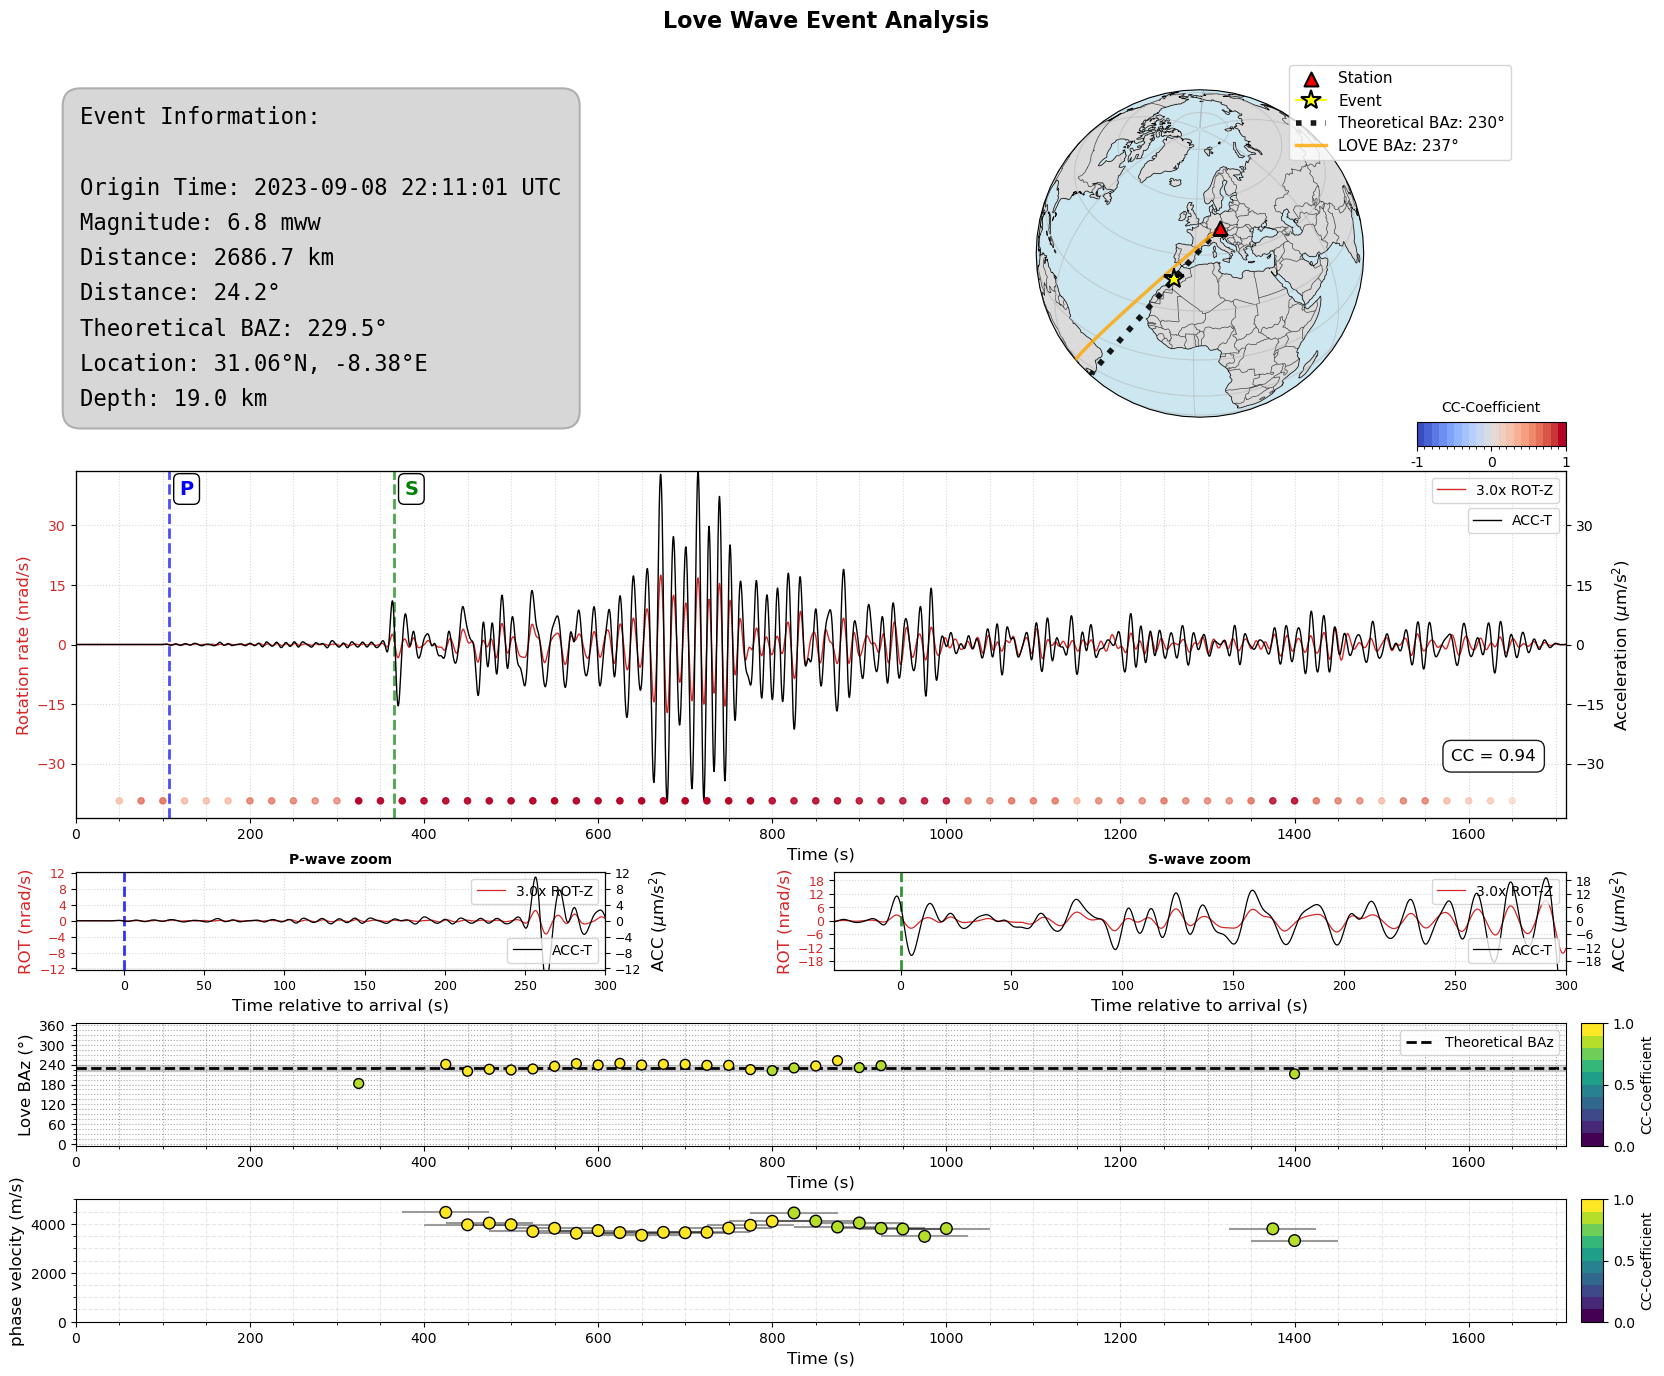

In [46]:
fig = plot_event_overview(sd, 
    baz_results_love,
    love_velocities,
    event_info=ev,
    wave_type='love',
    baz_theo=ev['backazimuth'],
    cc_threshold=config['cc_threshold'],
    vmax=5000,
    cc_method='mid',
    twin_sec=config['twin_sec'],
    twin_overlap=config['twin_overlap'],
    zoom_t1=30,
    zoom_t2=300
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_gring_event_overview_love_mid.png")